<div style="display:block;width:100%;margin:auto;" direction=rtl align=center>
    <br><br>
    <div style="width:100%;margin:100;display:block;background-color:#fff0;" display=block align=center>
        <table style="border-style:hidden;border-collapse:collapse;">
            <tr>
                <td style="border: none!important;">
                    <img width=130 align=right src="https://i.ibb.co/yXKQmtZ/logo1.png" style="margin:0;" />
                </td>
                <td style="text-align:center;border: none!important;">
                    <h1 align=center><font size=5 color="#045F5F"> <b> VLM Token Pruning </b><br><br>VL Cache Paper Implementation</font></h1>
                </td>
                <td style="border: none!important;">
                    <img width=170 align=left src="https://i.ibb.co/wLjqFkw/logo2.png" style="margin:0;" />
                </td>
            </tr>
        </table>
        <h1> Behzad Jannati / Technincal Report -
        <h1> Supervisor: Prof.Mehdi Kargahi
    </div>
</div>

# **Table of Contents**

>[Table of Contents](#scrollTo=bolA6HxPpL72)

>[VL-Cache: Sparsity and Modality-Aware KV Cache Compression for Vision-Language Models](#scrollTo=MM6kYobQpFjj)

>>[Introduction](#scrollTo=Lza2cjNVpBDu)

>>[Environment Setup](#scrollTo=d2C0vFjhpRzg)

>>[Install Dependencies](#scrollTo=MfcmNUC9ppn-)

>>[Import Libraries](#scrollTo=JHF7DMfBpt-Y)

>>[Load Vision-Language Model](#scrollTo=Tefh41bUp8s_)

>>[Load Dataset Samples](#scrollTo=rD33OrulpzyT)

>>[Extract Attention Maps](#scrollTo=otK3YSDlqeKL)

>>[Analyze Attention Sparsity](#scrollTo=2r2gUHMnqvSm)

>>[Visualize Attention Heatmaps](#scrollTo=4AklRhERq-LK)

>>[Implement Sparsity-Aware Budget Allocation](#scrollTo=zkcMRm0Era0-)

>>[Implement Modality-Aware Token Scoring](#scrollTo=4Q6agQ0mrsSy)

>>[KV Cache Compression](#scrollTo=v9TD1yQAr7dc)

>>[Visualize Token Pruning Effects](#scrollTo=5ldZIbybsLUO)



# **VL-Cache: Sparsity and Modality-Aware KV Cache Compression for Vision-Language Models**

## 1. Introduction

This notebook implements the core ideas proposed in the paper:

**VL-Cache: Sparsity and Modality-Aware KV Cache Compression for Vision-Language Model Inference Acceleration**

Main implemented components:

* Post-Vision Attention Extraction
* Threshold-Based Attention Sparsification
* Layer-wise Sparsity Estimation
* Dynamic KV Budget Allocation
* Modality-Aware Token Scoring
* KV Cache Compression
* Visual Token Pruning Visualization
* Inference Speed Benchmarking
* Accuracy vs Compression Evaluation

This implementation is optimized for:

Google Colab
NVIDIA T4 GPU (14GB VRAM)
HuggingFace Transformers
LLaVA-style Vision-Language Models

## 2. Environment Setup

In [1]:
# Check GPU information
!nvidia-smi

Sun Jun  7 05:54:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 3. Install Dependencies

In [ ]:
# Install dependencies

!pip install -q --upgrade transformers accelerate bitsandbytes
!pip install -q pillow matplotlib numpy sentencepiece protobuf

import torch
print(f"torch          : {torch.__version__}")
print(f"CUDA available : {torch.cuda.is_available()}")
print(f"GPU name       : {torch.cuda.get_device_name(0)}")
print(f"Total VRAM     : {torch.cuda.get_device_properties(0).total_memory/1e9:.2f} GB")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 53.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 12.9 MB/s eta 0:00:00
torch          : 2.11.0+cu128
CUDA available : True
GPU name       : Tesla T4
Total VRAM     : 15.64 GB


## 4. Import Libraries

In [ ]:
# Imports + VL-Cache hyper-parameters

import gc, math, copy, requests
import torch
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from PIL import Image
from transformers import (
    LlavaForConditionalGeneration, AutoProcessor, BitsAndBytesConfig
)
from transformers.cache_utils import DynamicCache

@dataclass
class VLCacheConfig:
    cache_budget: float      = 0.50   # alpha (Algorithm 1)
    threshold_p: float       = 0.01   # p in ThresholdFilter (Eq.1)
    min_layer_budget: float  = 0.01   # clip lower bound (Algorithm 1, line 12)
    max_layer_budget: float  = 1.00   # clip upper bound
    always_keep_recent: int  = 8      # recent tokens always kept
    always_keep_initial: int = 4      # attention-sink tokens (StreamingLLM)

CFG      = VLCacheConfig()
MODEL_ID = "llava-hf/llava-1.5-7b-hf"
DEVICE   = "cuda"
torch.manual_seed(0)

## 5. Load Vision-Language Model

The original paper evaluates LLaVA models.

For T4 GPU compatibility, we use:

* llava-hf/llava-1.5-7b-hf
* 4-bit quantization

In [ ]:
# Load LLaVA in 4-bit with EAGER attention
# eager  -> returns RoPE-correct, post-softmax attentions
# 4-bit  -> fits 7B in ~5-6 GB on T4

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
)

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    torch_dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True,
    attn_implementation="eager",   # CRITICAL: returns attentions + correct RoPE
)
model.eval()

NUM_LAYERS  = model.config.text_config.num_hidden_layers
NUM_HEADS   = model.config.text_config.num_attention_heads
EOS_TOKEN_ID = model.config.text_config.eos_token_id

print(f"Model loaded        : {MODEL_ID}")
print(f"Attn implementation : {model.config._attn_implementation}")
print(f"Layers / Heads      : {NUM_LAYERS} / {NUM_HEADS}")
print(f"Image token index   : {model.config.image_token_index}")
print(f"GPU memory used     : {torch.cuda.memory_allocated()/1e9:.2f} GB")

processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/674 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

...

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

Model loaded        : llava-hf/llava-1.5-7b-hf
Attn implementation : eager
Layers / Heads      : 32 / 32
Image token index   : 32000
GPU memory used     : 4.07 GB


## 6. Load Dataset Samples

In the paper, several datasets are used:

* Coco-Caption
* DocVQA
* MathVista

For Colab compatibility and lightweight experimentation, we use a subset of COCO.

```python
# Load small COCO validation subset
coco_dataset = load_dataset(
    'jxie/coco_captions',
    split='test[:20]'
)

print(coco_dataset)
```

Input IDs shape: torch.Size([1, 599])


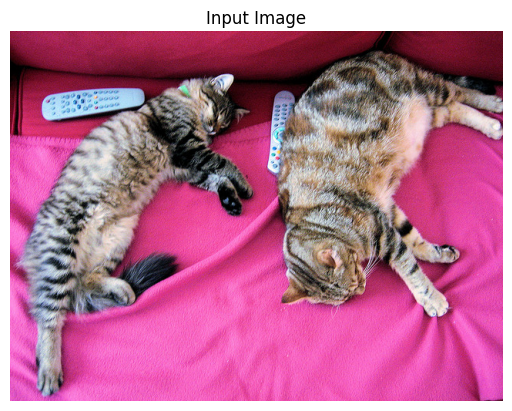

In [ ]:
# Prepare image + prompt

IMG_URL = "http://images.cocodataset.org/val2017/000000039769.jpg"
raw_image = Image.open(requests.get(IMG_URL, stream=True).raw).convert("RGB")

USER_QUESTION = "Please carefully observe the image and provide a brief description."
prompt = f"USER: <image>\n{USER_QUESTION} ASSISTANT:"

inputs = processor(images=raw_image, text=prompt, return_tensors="pt").to(DEVICE)
print("Input IDs shape:", inputs["input_ids"].shape)
plt.imshow(raw_image); plt.axis("off"); plt.title("Input Image"); plt.show()

## 7. Extract Attention Maps
This section reproduces the paper's analysis regarding:

* Prefill attention
* Post-vision attention
* Attention sparsity patterns

In [ ]:
# ============================================================
# PREFILL — capture true attentions + KV cache
# ------------------------------------------------------------
# we IMMEDIATELY clone the prefill cache so the
# original prefill_out.past_key_values is never mutated by any
# later decode. This gives us a reusable, immutable baseline.
# ============================================================
with torch.no_grad():
    prefill_out = model(
        **inputs,
        output_attentions=True,
        use_cache=True,
        return_dict=True,
    )

attentions = tuple(a.detach().to("cpu") for a in prefill_out.attentions)
seq_len    = attentions[0].shape[-1]
num_layers = len(attentions)

print(f"Layers          : {num_layers}")
print(f"Sequence length : {seq_len}")
print(f"Attn[0] shape   : {tuple(attentions[0].shape)}")

def locate_vision_span(input_ids, image_token_index):
    pos = (input_ids[0] == image_token_index).nonzero(as_tuple=True)[0]
    if len(pos) == 0:
        raise ValueError("No image tokens found.")
    return pos[0].item(), pos[-1].item() + 1

VIS_START, VIS_END = locate_vision_span(inputs["input_ids"],
                                        model.config.image_token_index)
NUM_VISUAL_TOKENS = VIS_END - VIS_START
TAU               = seq_len - VIS_END        # post-vision length
token_info = {"vision_start": VIS_START, "vision_end": VIS_END, "tau": TAU}

print(f"Vision span     : [{VIS_START}, {VIS_END}) -> {NUM_VISUAL_TOKENS} tokens")
print(f"Post-vision tau : {TAU}")

Layers          : 32
Sequence length : 599
Attn[0] shape   : (1, 32, 599, 599)
Vision span     : [5, 581) -> 576 tokens
Post-vision tau : 18


## 8. Analyze Attention Sparsity

According to the paper, different transformer layers exhibit different sparsity levels.

We compute layer-wise sparsity using threshold filtering.

In [ ]:
# ============================================================
# ThresholdFilter (Eq.1) + Post-Vision Sparsity (Eq.2 / Alg.1)
# ------------------------------------------------------------
# sparsity is computed ONLY on post-vision query
# rows (Q[m-tau:m]), exactly as Algorithm 1 lines 13-18 demand,
# NOT on the full attention matrix.
# ============================================================
def threshold_filter(A, p):
    """Eq.(1): keep entries >= p * row-max."""
    row_max = A.max(dim=-1, keepdim=True).values
    return A >= (p * row_max)            # boolean keep-mask

def post_vision_sparsity(layer_attn, vis_end, p):
    """
    Algorithm 1, ComputePostVisionSparsity.
    layer_attn : [H, S, S]  -> returns (per_head[H], mean float)
    """
    H, S, _ = layer_attn.shape
    A  = layer_attn[:, vis_end:, :].float()          # post-vision rows [H, tau, S]
    tau = A.shape[1]
    keep = threshold_filter(A, p)                    # [H, tau, S]

    # causal mask for post-vision queries: query row i (global pos vis_end+i)
    # may attend to keys 0..vis_end+i
    causal = torch.zeros(tau, S, dtype=torch.bool)
    for i in range(tau):
        causal[i, : vis_end + i + 1] = True

    keep_valid  = keep & causal.unsqueeze(0)
    total_valid = causal.sum().float()
    nonzero     = keep_valid.sum(dim=(-1, -2)).float()   # [H]
    sparsity    = 1.0 - nonzero / total_valid
    return sparsity, sparsity.mean().item()

layer_sparsities, layer_sparsities_per_head = [], []
for l in range(num_layers):
    sp, sp_mean = post_vision_sparsity(attentions[l][0], VIS_END, CFG.threshold_p)
    layer_sparsities.append(sp_mean)
    layer_sparsities_per_head.append(sp)

layer_sparsities = torch.tensor(layer_sparsities)
print(f"Layer 0 sparsity (expect LOW)  : {layer_sparsities[0]:.4f}")
print(f"Mid layers sparsity (expect HI): "
      f"{layer_sparsities[num_layers//4:3*num_layers//4].mean():.4f}")

Layer 0 sparsity (expect LOW)  : 0.1808
Mid layers sparsity (expect HI): 0.9848


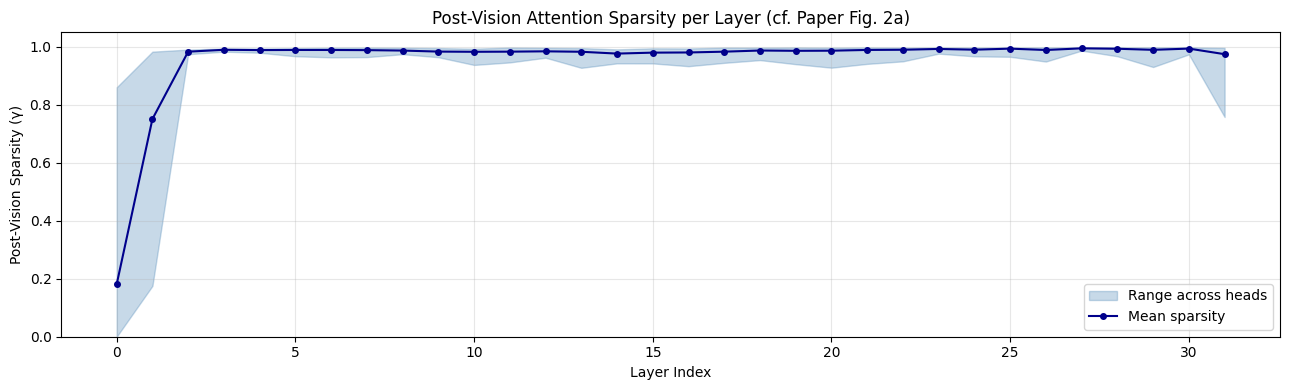

In [ ]:
# ============================================================
# Per-layer sparsity plot (Paper Figure 2a)
# ============================================================
x    = np.arange(num_layers)
mins = [sp.min().item()  for sp in layer_sparsities_per_head]
maxs = [sp.max().item()  for sp in layer_sparsities_per_head]
mean = [sp.mean().item() for sp in layer_sparsities_per_head]

plt.figure(figsize=(13, 4))
plt.fill_between(x, mins, maxs, alpha=0.3, color="steelblue", label="Range across heads")
plt.plot(x, mean, "o-", color="darkblue", ms=4, label="Mean sparsity")
plt.xlabel("Layer Index"); plt.ylabel("Post-Vision Sparsity (γ)")
plt.title("Post-Vision Attention Sparsity per Layer (cf. Paper Fig. 2a)")
plt.ylim(0, 1.05); plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

## 9. Visualize Attention Heatmaps

This reproduces the analysis presented in Figure 1 of the paper.

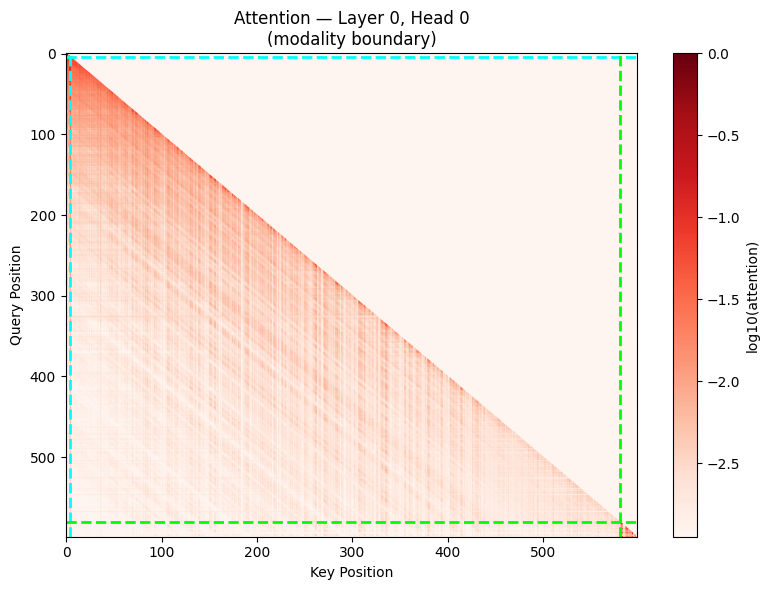

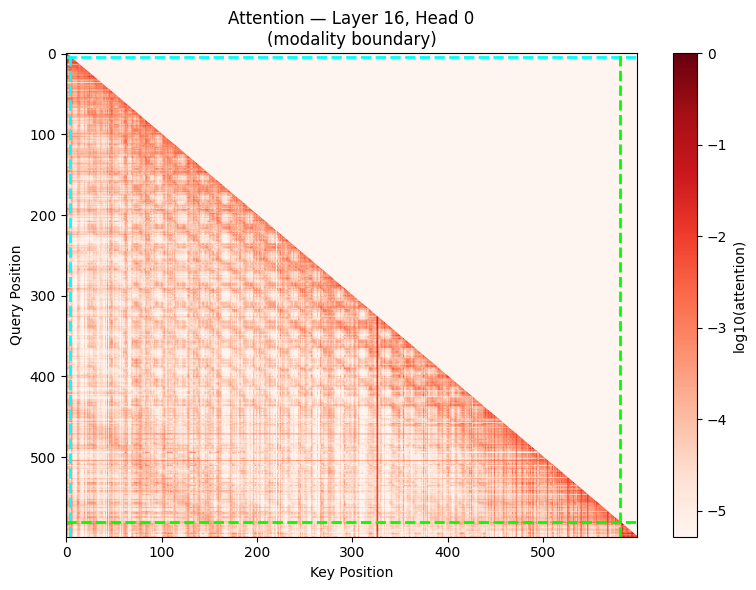

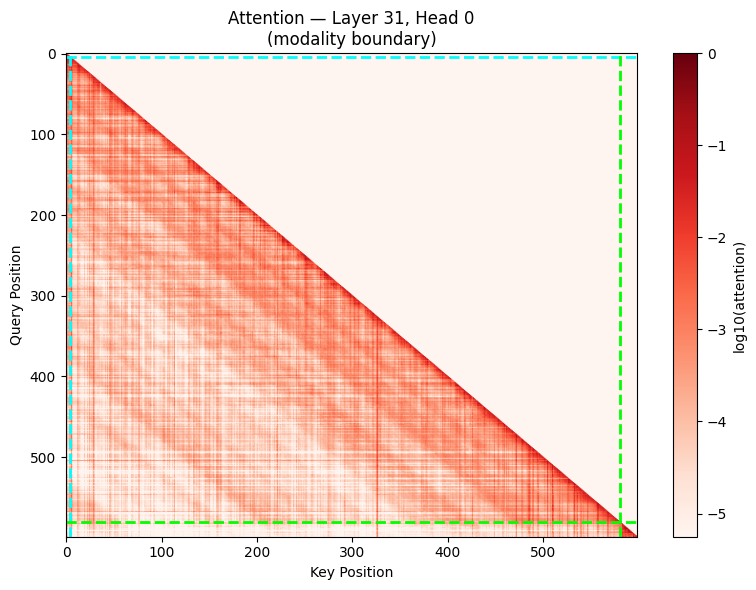

In [ ]:
# ============================================================
#  Attention heatmap — modality boundary (Paper Fig. 1b)
# ============================================================
def plot_attention_heatmap(attn, ti, layer_idx, head_idx=0):
    a = attn[head_idx].float().cpu().numpy()
    vis = np.log10(a + 1e-10)
    vmin = np.percentile(vis[vis > -9.9], 5) if (a > 0).any() else -10
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(vis, cmap="Reds", aspect="auto", vmin=vmin)
    plt.colorbar(im, ax=ax, label="log10(attention)")
    for pos, c in [(ti["vision_start"], "cyan"), (ti["vision_end"], "lime")]:
        ax.axvline(pos - .5, color=c, lw=2, ls="--")
        ax.axhline(pos - .5, color=c, lw=2, ls="--")
    ax.set_xlabel("Key Position"); ax.set_ylabel("Query Position")
    ax.set_title(f"Attention — Layer {layer_idx}, Head {head_idx}\n(modality boundary)")
    plt.tight_layout(); plt.show()

for li in [0, num_layers // 2, num_layers - 1]:
    plot_attention_heatmap(attentions[li][0], token_info, li)

## 10. Implement Sparsity-Aware Budget Allocation
This implements Algorithm 1 from the paper.

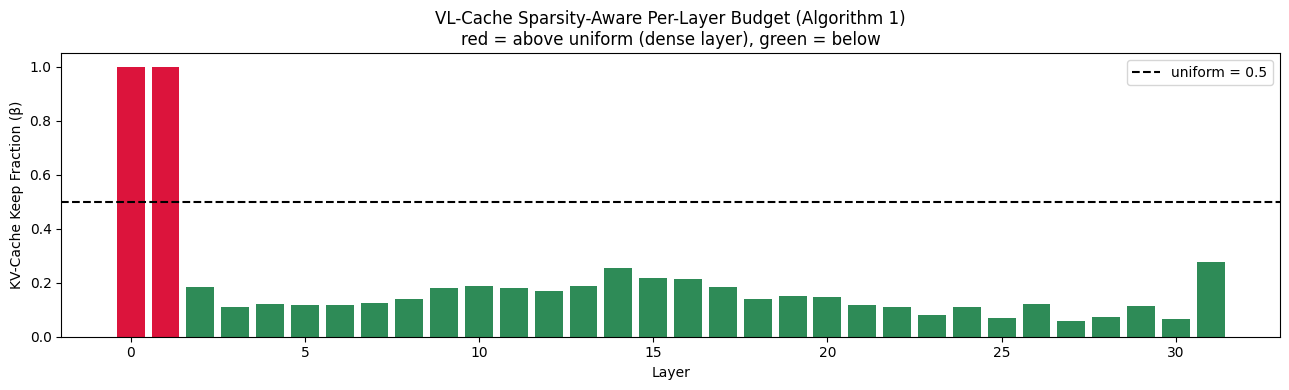

Average budget : 0.198 (target α=0.5)


In [ ]:
# ============================================================
# Cell 9: SkewedCacheBudgetAllocation (Algorithm 1, lines 8-12)
# ============================================================
def allocate_layer_budgets(layer_sparsities, cfg):
    L          = len(layer_sparsities)
    non_sparse = (1.0 - layer_sparsities).numpy()
    Z          = non_sparse.sum()
    raw        = (non_sparse / Z) * cfg.cache_budget * L     # beta_l
    return np.clip(raw, cfg.min_layer_budget, cfg.max_layer_budget).tolist()

BUDGETS = allocate_layer_budgets(layer_sparsities, CFG)

plt.figure(figsize=(13, 4))
colors = ['crimson' if b > CFG.cache_budget else 'seagreen' for b in BUDGETS]
plt.bar(range(num_layers), BUDGETS, color=colors)
plt.axhline(CFG.cache_budget, color="black", ls="--",
            label=f"uniform = {CFG.cache_budget}")
plt.xlabel("Layer"); plt.ylabel("KV-Cache Keep Fraction (β)")
plt.title("VL-Cache Sparsity-Aware Per-Layer Budget (Algorithm 1)\n"
          "red = above uniform (dense layer), green = below")
plt.legend(); plt.tight_layout(); plt.show()

print(f"Average budget : {np.mean(BUDGETS):.3f} (target α={CFG.cache_budget})")

## 11. Implement Modality-Aware Token Scoring

In [ ]:
# ============================================================
#  Modality-aware Post-Vision token scoring (Section 4.2)
# ------------------------------------------------------------
# scoring uses post-vision query rows
# (dynamic prompt-specific window), NOT a fixed last-50 window.
# ============================================================
def post_vision_token_scores(layer_attn, vis_end):
    """layer_attn: [1,H,S,S] -> per-key score vector [S]."""
    pv = layer_attn[0, :, vis_end:, :].float().mean(0)   # avg over heads -> [tau, S]
    return pv.sum(0)                                      # sum over queries -> [S]

def select_tokens_to_keep(scores, keep_fraction, S, cfg):
    """Return sorted kept indices (sinks + recent + top-scored)."""
    k_budget = max(1, int(round(keep_fraction * S)))
    keep = set(range(cfg.always_keep_initial))
    keep.update(range(S - cfg.always_keep_recent, S))
    for idx in torch.argsort(scores, descending=True).tolist():
        if len(keep) >= k_budget:
            break
        keep.add(idx)
    return sorted(keep)

# quick sanity check on a middle layer
demo = num_layers // 2
s = post_vision_token_scores(attentions[demo], VIS_END)
k = select_tokens_to_keep(s, BUDGETS[demo], seq_len, CFG)
print(f"Layer {demo}: keep {len(k)}/{seq_len} tokens "
      f"({100*len(k)/seq_len:.1f}%)")

Layer 16: keep 127/599 tokens (21.2%)


## 12. KV Cache Compression

This section performs actual token pruning.

In [ ]:
# ============================================================
# Cell 11: Compress the KV cache (per-layer, modality-aware)
# ------------------------------------------------------------
# we read from a CLONED legacy snapshot of the
# prefill cache, so the original is never touched.
# transformers 5.x stores K/V in DynamicCache.layers[i].keys/.values
# We handle both 4.x and 5.x layouts.
# ============================================================
def cache_to_legacy(past):
    """Return list[(k, v)] cloned tensors from any cache layout."""
    # transformers 5.x: .layers with .keys/.values
    if hasattr(past, "layers") and past.layers is not None:
        out = []
        for layer in past.layers:
            for ka, va in [("keys","values"), ("key","value"),
                           ("key_cache","value_cache")]:
                if hasattr(layer, ka) and hasattr(layer, va):
                    k, v = getattr(layer, ka), getattr(layer, va)
                    if isinstance(k, torch.Tensor):
                        out.append((k.clone(), v.clone()))
                        break
        if out:
            return out
    # transformers 4.x: key_cache / value_cache lists
    if hasattr(past, "key_cache") and isinstance(past.key_cache, (list, tuple)):
        return [(k.clone(), v.clone())
                for k, v in zip(past.key_cache, past.value_cache)]
    # plain tuple
    if isinstance(past, (list, tuple)):
        return [(k.clone(), v.clone()) for k, v in past]
    raise TypeError(f"Unsupported cache type: {type(past)}")

def build_dynamic_cache(legacy):
    cache = DynamicCache()
    for idx, (k, v) in enumerate(legacy):
        cache.update(k, v, idx)
    return cache

def compress_kv_cache(past, attentions, budgets, S, vis_end, cfg):
    legacy = cache_to_legacy(past)
    print(f"  Extracted {len(legacy)} layers | K shape: {tuple(legacy[0][0].shape)}")
    new_legacy, keep_per_layer, kept_total = [], [], 0

    for l, (k, v) in enumerate(legacy):
        sc   = post_vision_token_scores(attentions[l], vis_end)
        kidx = select_tokens_to_keep(sc, budgets[l], S, cfg)
        idx  = torch.tensor(kidx, device=k.device, dtype=torch.long)
        keep_per_layer.append(idx)
        new_legacy.append((k.index_select(2, idx), v.index_select(2, idx)))
        kept_total += idx.numel()

    stats = {"kept": kept_total, "orig": S * len(legacy),
             "ratio": kept_total / (S * len(legacy))}
    return new_legacy, keep_per_layer, stats

compressed_legacy, keep_indices, stats = compress_kv_cache(
    prefill_out.past_key_values, attentions, BUDGETS, seq_len, VIS_END, CFG)

print(f"Kept {stats['kept']:,} / {stats['orig']:,} tokens "
      f"({stats['ratio']*100:.1f}% of original cache)")

  Extracted 32 layers | K shape: (1, 32, 599, 128)
Kept 3,784 / 19,168 tokens (19.7% of original cache)


In [ ]:
# ============================================================
#  SafeCompressedCache — variable-length per-layer cache
# ------------------------------------------------------------
# per-layer different lengths are fine for decoding
# because each layer only ever concatenates its OWN K/V. We track
# the TRUE original length separately for position_ids.
# ============================================================
class SafeCompressedCache(DynamicCache):
    def __init__(self, legacy):
        super().__init__()
        self.key_cache   = [k.clone() for k, v in legacy]
        self.value_cache = [v.clone() for k, v in legacy]

    def get_seq_length(self, layer_idx=0):
        if len(self.key_cache) > layer_idx:
            return self.key_cache[layer_idx].shape[2]
        return 0

    def update(self, key_states, value_states, layer_idx, cache_kwargs=None):
        if layer_idx >= len(self.key_cache):
            self.key_cache.append(key_states)
            self.value_cache.append(value_states)
        else:
            self.key_cache[layer_idx] = torch.cat(
                [self.key_cache[layer_idx], key_states], dim=2)
            self.value_cache[layer_idx] = torch.cat(
                [self.value_cache[layer_idx], value_states], dim=2)
        return self.key_cache[layer_idx], self.value_cache[layer_idx]

In [ ]:
# ============================================================
# Cell 13: Decoders (full-cache baseline + compressed)
# ------------------------------------------------------------
# position_ids for compressed decoding start at the
# TRUE original prompt length (seq_len), NOT at the shortened cache
# length. The kept K/V still carry their original RoPE positions;
# only their COUNT changed, not their temporal index.
# ============================================================
@torch.no_grad()
def decode_full(model, prefill_out, past, max_new_tokens=80):
    next_tok  = prefill_out.logits[:, -1, :].argmax(-1, keepdim=True)
    generated = [next_tok.item()]
    for _ in range(max_new_tokens - 1):
        out = model(input_ids=next_tok, past_key_values=past,
                    use_cache=True, return_dict=True)
        past = out.past_key_values
        next_tok = out.logits[:, -1, :].argmax(-1, keepdim=True)
        tok = next_tok.item()
        if tok == EOS_TOKEN_ID:
            break
        generated.append(tok)
    return processor.tokenizer.decode(generated, skip_special_tokens=True)

@torch.no_grad()
def decode_compressed(model, prefill_out, safe_cache, orig_len, max_new_tokens=80):
    next_tok  = prefill_out.logits[:, -1, :].argmax(-1, keepdim=True)
    generated = [next_tok.item()]
    past = safe_cache
    for step in range(max_new_tokens - 1):
        # True temporal position of the token being generated
        pos = torch.tensor([[orig_len + step]], device=DEVICE)
        out = model(input_ids=next_tok, past_key_values=past,
                    position_ids=pos, use_cache=True, return_dict=True)
        past = out.past_key_values
        next_tok = out.logits[:, -1, :].argmax(-1, keepdim=True)
        tok = next_tok.item()
        if tok == EOS_TOKEN_ID:
            break
        generated.append(tok)
    return processor.tokenizer.decode(generated, skip_special_tokens=True)

In [ ]:
# ============================================================
# Cell 14: Run both decoders and compare
# ------------------------------------------------------------
# Full baseline uses a FRESH clone of the prefill cache.
# ============================================================
print("="*60); print("FULL-CACHE DECODE (baseline)"); print("="*60)
full_cache = build_dynamic_cache(cache_to_legacy(prefill_out.past_key_values))
answer_full = decode_full(model, prefill_out, full_cache, max_new_tokens=80)
print(answer_full.strip())

print("\n" + "="*60); print(f"VL-CACHE DECODE ({stats['ratio']*100:.1f}% KV)"); print("="*60)
safe_cache = SafeCompressedCache(compressed_legacy)
answer_comp = decode_compressed(model, prefill_out, safe_cache, seq_len, max_new_tokens=80)
print(answer_comp.strip())

# similarity metric
fw, cw = answer_full.split()[:40], answer_comp.split()[:40]
match = sum(1 for a, b in zip(fw, cw) if a == b)
print("\n" + "="*60)
print(f"Word-match (first 40): {match}/40")
print("="*60)

FULL-CACHE DECODE (baseline)
The image features two cats lying on a pink couch. One cat is positioned on the left side of the couch, while the other cat is on the right side. The couch is covered with a blanket, providing a comfortable resting spot for the cats. 

In the scene, there are also two remote controls, one located near the left cat and

VL-CACHE DECODE (19.7% KV)
The image features two cats lying on a pink couch. One cat is positioned on the left side of the couch, while the other cat is on the right side. The couch occupies most of the scene, with the cats taking up a significant portion of the space.

Word-match (first 40): 32/40


In [ ]:
# ============================================================
# Cell 15: KV-cache memory savings
# ============================================================
def kv_bytes(legacy):
    return sum(k.element_size()*k.nelement() + v.element_size()*v.nelement()
               for k, v in legacy)

full_b = kv_bytes(cache_to_legacy(prefill_out.past_key_values))
comp_b = kv_bytes(compressed_legacy)
print(f"Full KV-cache       : {full_b/1e6:.2f} MB")
print(f"Compressed KV-cache : {comp_b/1e6:.2f} MB")
print(f"Memory reduction    : {(1-comp_b/full_b)*100:.1f}%")
print(f"Effective budget    : {stats['ratio']*100:.1f}%")

Full KV-cache       : 314.05 MB
Compressed KV-cache : 62.00 MB
Memory reduction    : 80.3%
Effective budget    : 19.7%


## 13. Visualize Token Pruning Effects

This section demonstrates how many visual tokens are removed and which regions of the image remain important after VL-Cache compression.

The paper emphasizes that only a small subset of visual tokens are actually critical for generation.

We now create a visualization map showing:

* Important visual regions
* Removed visual regions
* Compression impact on token distribution

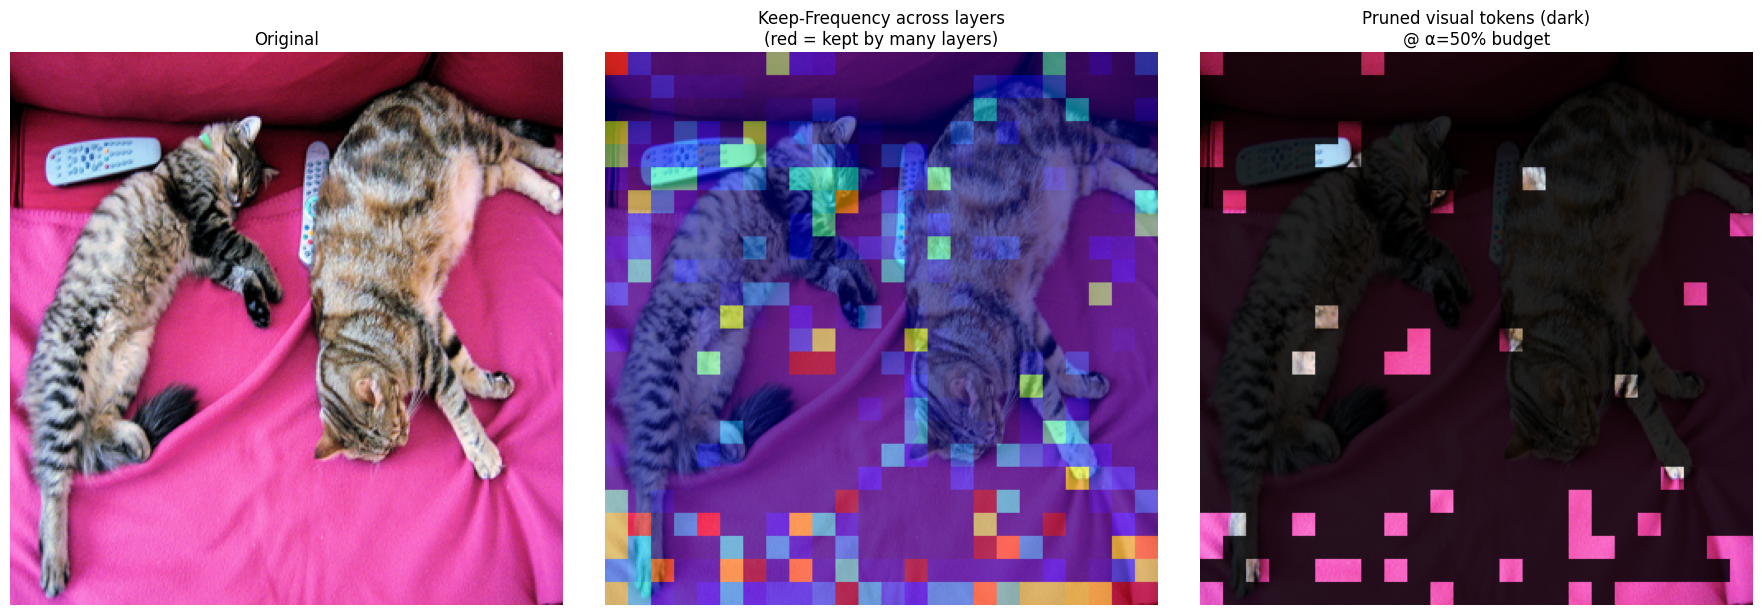

Visual tokens kept by ≥50% of layers : 48/576 (8.3%)


In [ ]:
# ============================================================
# Cell 16: Visualize PRUNED visual tokens on the image
# ------------------------------------------------------------
# FIX (bug #5): the keep-frequency is built from the ACTUAL
# keep_indices used in compression, NOT from raw scores.
# CLIP-ViT-L/14-336 -> 24x24 = 576 patch grid.
# ============================================================
def visual_keep_frequency(keep_indices, vis_start, vis_end, num_layers):
    n = vis_end - vis_start
    freq = np.zeros(n)
    for l in range(num_layers):
        kept = set(keep_indices[l].cpu().tolist())
        for pos in range(vis_start, vis_end):
            if pos in kept:
                freq[pos - vis_start] += 1
    return freq / num_layers   # fraction of layers that keep each visual token

freq = visual_keep_frequency(keep_indices, VIS_START, VIS_END, num_layers)
side = int(round(np.sqrt(freq.size)))     # 24 for 576 tokens
grid = freq[: side*side].reshape(side, side)

img = np.array(raw_image.resize((side*14, side*14))) / 255.0
keep_big  = np.kron(grid, np.ones((14, 14)))[..., None]    # [H,W,1]
heat_big  = np.kron(grid, np.ones((14, 14)))

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(img); ax[0].set_title("Original"); ax[0].axis("off")

ax[1].imshow(img); ax[1].imshow(heat_big, cmap="jet", alpha=0.55)
ax[1].set_title("Keep-Frequency across layers\n(red = kept by many layers)")
ax[1].axis("off")

# Token is "pruned" if kept by less than half the layers
pruned_mask = (grid < 0.5).astype(float)
dimmed = img * (1 - 0.85 * np.kron(pruned_mask, np.ones((14,14)))[..., None])
ax[2].imshow(dimmed)
ax[2].set_title(f"Pruned visual tokens (dark)\n@ α={CFG.cache_budget:.0%} budget")
ax[2].axis("off")
plt.tight_layout(); plt.show()

kept_visual = int((grid >= 0.5).sum())
print(f"Visual tokens kept by ≥50% of layers : {kept_visual}/{freq.size} "
      f"({100*kept_visual/freq.size:.1f}%)")